# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

%precision 3

'%.3f'

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

In [3]:
import numpy as np

# Đặt seed để chạy lại ra đúng kết quả này (các lượt đánh thử ngẫu nhiên ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [4]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

-1
1
1
1
1


**Nhận xét.** Mỗi lần gọi `playout` là một ván đánh thử: hai bên đều đi bừa tới hết ván, rồi trả về `+1` (x thắng), `0` (hòa) hoặc `-1` (x thua). Với seed `20261110`, năm ván thử cho ra `-1, 1, 1, 1, 1`: x thắng 4 ván, thua 1 ván. Chỉ vài ván thì chưa nói được gì, nên cần đánh thử nhiều ván và lấy trung bình (ô tiếp theo).

In [5]:
# Đặt seed để chạy lại ra đúng kết quả này (100 lượt đánh thử ngẫu nhiên ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [6]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

u = playouts(board, 0)
print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

p_win = sum(np.array(u) == +1)/len(u)
p_loss = sum(np.array(u) == -1)/len(u)
p_draw = sum(np.array(u) == 0)/len(u)
print(f"win probability: {p_win}")
print(f"loss probability: {p_loss}")
print(f"draw probability: {p_draw}")

Playout results: [-1, 1, 1, 1, 1, 0, 1, 1, -1, 1, 1, 1, 1, 1, 0, 1, -1, 1, -1, 1, 1, -1, 1, -1, -1, 1, 1, 1, 1, 0, 1, -1, 1, -1, -1, 1, -1, 1, -1, 1, -1, -1, 1, 1, 1, -1, 1, 0, 1, 0, 1, 1, -1, -1, 0, 1, 1, 0, 1, 1, 1, 0, 1, -1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, -1, -1, 1, 1, 0, 1, 0, -1, 1, -1, 1, 1, 1, 1, -1, -1, -1, 0, -1, 1, 1, -1, 1, -1, -1, 1]
mean utility: 0.29
win probability: 0.58
loss probability: 0.29
draw probability: 0.13


**Nhận xét.** Sau 100 ván đánh thử bắt đầu từ ô 0, x thắng 58 ván (0.58), thua 29 ván (0.29) và hòa 13 ván (0.13), điểm trung bình là 0.29. Hai bên đều đi bừa mà x (người đi trước) vẫn thắng gần gấp đôi o, nên **đi trước có lợi thế rõ**. Điều này cũng giải thích vì sao khi Monte Carlo đi sau (Bảng 2 bên dưới) thì khó thắng hơn.

__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

In [7]:
# Đặt seed để chạy lại ra đúng kết quả này (pmcs ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [8]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get)
    return action

board = empty_board()
display(board)
%time print(pmcs(board))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.545,
 1: 0.000,
 2: 0.182,
 3: 0.091,
 4: 0.636,
 5: 0.273,
 6: 0.182,
 7: 0.273,
 8: -0.182}

4
CPU times: user 29.9 ms, sys: 2 ms, total: 31.9 ms
Wall time: 30.3 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.347,
 1: 0.210,
 2: 0.340,
 3: 0.228,
 4: 0.507,
 5: 0.213,
 6: 0.362,
 7: 0.221,
 8: 0.345}

4
CPU times: user 3 s, sys: 102 ms, total: 3.1 s
Wall time: 2.97 s


**Nhận xét.** Ở bàn trống, 100 ván chia cho 9 ô chỉ được 11 ván mỗi ô, nên điểm trung bình của từng ô dao động mạnh (từ -0.182 ở ô 8 tới 0.636 ở ô 4); lần này ô 4 (chính giữa) thắng với 0.636. Với 10,000 ván (1,111 ván mỗi ô) các điểm gần nhau hơn và rõ ràng hơn: ô giữa 0.507, bốn góc 0.340 - 0.362, bốn cạnh 0.210 - 0.228. Ô giữa vẫn được chọn nhưng chạy chậm hơn nhiều (khoảng 3 giây so với 31 ms). Càng nhiều ván đánh thử thì ước lượng càng chính xác, nhưng càng tốn thời gian.

Looks like the center and the corners are a lot better.

## Some Tests

### x is about to win (play 8)


In [9]:
# Đặt seed để chạy lại ra đúng kết quả này (pmcs ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


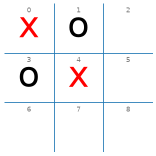


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.900, 5: 0.550, 6: 0.950, 7: 0.650, 8: 1.000}

8

CPU times: user 14.6 ms, sys: 991 μs, total: 15.6 ms
Wall time: 14.9 ms


In [10]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

**Nhận xét.** x thắng ngay nếu đi ô 8, và ô 8 có điểm 1.000 (20 ván thử đều thắng). Các nước khác thấp hơn vì sau đó o còn cơ hội đi bừa vào ô chặn (ô 2: 0.900, ô 6: 0.950, ô 5: 0.550, ô 7: 0.650). Pure Monte Carlo chọn đúng ô 8 trong khoảng 15 ms.

### o is about to win

In [11]:
# Đặt seed để chạy lại ra đúng kết quả này (pmcs ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


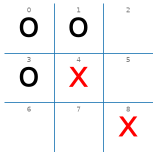


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: 0.120, 5: -0.520, 6: 0.120, 7: -0.440}

2

CPU times: user 12 ms, sys: 30 μs, total: 12 ms
Wall time: 11.6 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: 0.016, 5: -0.656, 6: 0.016, 7: -0.696}

2

CPU times: user 94.7 ms, sys: 4.01 ms, total: 98.7 ms
Wall time: 95.7 ms


In [12]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

**Nhận xét.** Ở thế cờ này o có hai đường dọa thắng cùng lúc (ô 2 và ô 6), x chỉ chặn được một đường nên thực ra mọi nước đều thua nếu o chơi đúng (kiểm tra ở Bảng "Nước tối ưu" bên dưới). Pure Monte Carlo cho điểm cao nhất cho ô 2 và ô 6 (0.120 với N = 100; 0.016 với N = 1000), tức là hai ô chặn đúng, còn ô 5 và ô 7 (-0.52, -0.44) bị điểm rất thấp. Hai ô 2 và 6 bằng điểm nhau nên máy lấy ô bên trái (ô 2). Điểm trung bình gần 0 chứ không phải -1 vì o chỉ thắng khi nó đi bừa mà vô tình chọn đúng ô thắng.

### x can draw if it chooses 7

In [13]:
# Đặt seed để chạy lại ra đúng kết quả này (pmcs ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


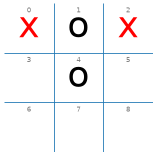


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: -0.400, 5: -0.150, 6: -0.150, 7: -0.050, 8: -0.300}

7

CPU times: user 16.9 ms, sys: 1.03 ms, total: 17.9 ms
Wall time: 17.1 ms


In [14]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

**Nhận xét.** Ô 7 là nước **duy nhất** giữ được hòa. Lần chạy này với N = 100 Pure Monte Carlo chọn đúng ô 7 (điểm -0.050, cao nhất), nhưng các điểm đều sát nhau (từ -0.400 đến -0.050) vì mỗi ô chỉ có 20 ván thử. Ở Bảng 1 bên dưới chạy 20 lần với 20 seed khác nhau, N = 100 chỉ chọn ô 7 ở 17/20 lần, nên lần chạy này chưa chắc luôn đúng.

### Empty board: Only a draw an be guaranteed

In [15]:
# Đặt seed để chạy lại ra đúng kết quả này (pmcs ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


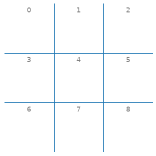


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.328,
 1: 0.213,
 2: 0.348,
 3: 0.249,
 4: 0.548,
 5: 0.171,
 6: 0.348,
 7: 0.193,
 8: 0.326}

4

CPU times: user 1.53 s, sys: 43.3 ms, total: 1.57 s
Wall time: 1.51 s


In [16]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

**Nhận xét.** Với 5,000 ván (555 ván mỗi ô), ô giữa (ô 4) có điểm cao nhất 0.548, bốn góc từ 0.326 đến 0.348, bốn cạnh từ 0.171 đến 0.249. Kết quả này giống ô 11: ô giữa tốt nhất, rồi tới góc, cạnh yếu nhất. Chạy khoảng 1.5 giây trên máy này.

### A bad situation

In [17]:
# Đặt seed để chạy lại ra đúng kết quả này (pmcs ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

Board:


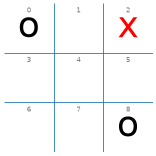


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -0.875, 3: -0.562, 4: -0.125, 5: -0.750, 6: -0.125, 7: -0.250}

4

CPU times: user 17.8 ms, sys: 24 μs, total: 17.8 ms
Wall time: 17.2 ms


In [18]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

**Nhận xét.** Đây là thế cờ "bất lợi": thực ra mọi nước đều thua nếu đối thủ chơi đúng (kiểm tra ở Bảng "Nước tối ưu"). Nhưng Pure Monte Carlo vẫn chọn ô 4 (điểm -0.125, cao nhất; ô 6 cũng -0.125 nhưng đứng sau theo thứ tự ô). Lý do là ván đánh thử cho **o đi bừa**: o rất ít khi vô tình đi vào ô 6 để thắng, nên x đỡ thua hơn thực tế. Như ghi chú của thầy bên dưới, Pure Monte Carlo ngầm cho rằng đối thủ chơi ngẫu nhiên.

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [19]:
# Đặt seed để chạy lại ra đúng kết quả này (ván đấu ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [20]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action


DEBUG = 1
print("PMCS vs. random:")
display(play(pmcs10_player, random_player, N = 1))

PMCS vs. random:
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: -1.000,
 1: 1.000,
 2: 1.000,
 3: 0.000,
 4: 1.000,
 5: -1.000,
 6: 1.000,
 7: 1.000,
 8: 1.000}

Actions: [0, 2, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: -1.000, 2: 1.000, 4: 1.000, 5: 0.000, 6: 1.000, 7: 1.000, 8: 1.000}

Actions: [4, 5, 6, 7, 8] (10 total playouts = 2 playouts per action)


{4: 0.000, 5: 1.000, 6: 1.000, 7: -1.000, 8: 0.000}

Actions: [4, 6, 8] (10 total playouts = 3 playouts per action)


{4: -0.333, 6: 1.000, 8: 1.000}

Actions: [4] (10 total playouts = 10 playouts per action)


{4: 1.000}

{'x': 1, 'o': 0, 'd': 0}

In [21]:
# Đặt seed để chạy lại ra đúng kết quả này (100 ván đấu ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [22]:
DEBUG = 0
print("PMCS (10) vs. random:")
%time display(play(pmcs10_player, random_player))

print()
print("random vs. PMCS (10)")
%time display(play(random_player, pmcs10_player))

PMCS (10) vs. random:


{'x': 89, 'o': 5, 'd': 6}

CPU times: user 635 ms, sys: 20.1 ms, total: 655 ms
Wall time: 628 ms

random vs. PMCS (10)


{'x': 22, 'o': 70, 'd': 8}

CPU times: user 456 ms, sys: 11.1 ms, total: 467 ms
Wall time: 452 ms


**Nhận xét (đấu với Random, N = 10).** Với seed `20261110`, PMCS (10) đi trước thắng 89 ván, hòa 6, thua 5. Đi sau thì thắng 70 ván, hòa 8, thua 22 (kết quả của `play` tính theo `'x'`/`'o'`: ở dòng "random vs. PMCS (10)", o là PMCS nên `'o': 70` là số ván PMCS thắng). (Số này hơi khác Bảng 2 bên dưới: ở ô này hai lượt đấu dùng chung một seed ban đầu, còn Bảng 2 đặt lại seed trước mỗi lượt.) N = 10 chỉ có 1 - 2 ván thử cho mỗi nước nên vẫn thắng Random khá nhiều nhưng còn thua khoảng 5% - 22%.

In [23]:
# Đặt seed để chạy lại ra đúng kết quả này (100 ván đấu ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [24]:
DEBUG = 0
print("PMCS (100) vs. random:")
%time display(play(pmcs100_player, random_player))

print()
print("random vs. PMCS (100)")
%time display(play(random_player, pmcs100_player))

PMCS (100) vs. random:


{'x': 98, 'o': 2, 'd': 0}

CPU times: user 6.63 s, sys: 193 ms, total: 6.82 s
Wall time: 6.63 s

random vs. PMCS (100)


{'x': 4, 'o': 94, 'd': 2}

CPU times: user 5.32 s, sys: 149 ms, total: 5.47 s
Wall time: 5.28 s


**Nhận xét (đấu với Random, N = 100).** PMCS (100) đi trước thắng 98 ván, thua 2 và không hòa. Đi sau thắng 94 ván, hòa 2, thua 4 (ở dòng "random vs. PMCS (100)", `'o': 94` là số ván PMCS thắng). So với N = 10 ở ô trên, thua ít hơn rõ rệt, nhưng chậm hơn khoảng 10 lần (khoảng 6.5 giây cho 100 ván, so với khoảng 0.6 giây). Cũng như ô trên, số đi sau ở đây hơi khác Bảng 2 vì chỉ đặt seed một lần cho cả hai lượt.

In [25]:
# Đặt seed để chạy lại ra đúng kết quả này (100 ván đấu ở ô bên dưới). Seed gốc của Thắng: 20261110.
np.random.seed(20261110)

In [26]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 86, 'o': 4, 'd': 10}

CPU times: user 7.13 s, sys: 197 ms, total: 7.32 s
Wall time: 7.03 s

PMCS (10) vs. PMCS (100)


{'x': 35, 'o': 50, 'd': 15}

CPU times: user 5.7 s, sys: 149 ms, total: 5.85 s
Wall time: 5.63 s


**Nhận xét (PMCS đấu PMCS).** PMCS (100) đi trước thắng PMCS (10) 86 ván, hòa 10, thua 4. Khi đổi chỗ, PMCS (10) đi trước thì chỉ thắng 35 ván còn thua 50 ván (ở dòng "PMCS (10) vs. PMCS (100)", `'o': 50` là số ván PMCS (100) thắng khi đi sau), hòa 15. Cùng thuật toán, chỉ khác số ván đánh thử, mà bên N = 100 thắng nhiều hơn dù đi trước (86 so với 4) hay đi sau (50 so với 35).

**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.

## Bài 5 — Độ ổn định, thời gian và bảng kết quả

Phần này là phần **thêm mới** của Toàn Thắng (các ô gốc của thầy ở trên giữ nguyên, mình chỉ chèn thêm ô đặt seed và ô nhận xét). Mục tiêu theo đề (Bài 5):

* Thử `pmcs` với **N = 10, 100, 1000** trên **cùng các trạng thái kiểm thử**, xem nước đi có **ổn định** không và mất bao nhiêu **thời gian**.
* Cho `pmcs10_player`, `pmcs100_player` (và thêm `pmcs1000_player`) đấu với `random_player`, rồi điền bảng thắng / hòa / thua.

Vài từ cần biết:

* **Playout** = "đánh thử một ván ngẫu nhiên tới hết". Hai bên đều đi bừa, rồi xem ai thắng.
* **Pure Monte Carlo** = với mỗi nước có thể đi, đánh thử nhiều ván như vậy, rồi chọn nước có kết quả trung bình tốt nhất. Tổng N ván được chia **đều** cho các nước (`n = N // số nước`).

**Cách chạy lại.** Mọi chỗ có ngẫu nhiên đều đặt seed ngay trước đó (seed gốc `20261110`; khi lặp 20 lần thì lần `r` dùng seed `20261110 + r`). Chạy lại với cùng seed sẽ ra đúng số này; đổi seed thì số đổi một chút. **Thời gian đo trên máy của người chạy**, máy khác sẽ khác.

In [27]:
import time
from collections import Counter

import pandas as pd

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)

DEBUG = 0          # im lặng khi chạy lặp nhiều lần
SEED = 20261110    # seed gốc của Thắng (Tú dùng 20261108, Thiện dùng 20261109)


def board_with(x = [], o = []):
    """bàn Tic-Tac-Toe có quân x ở các ô x và quân o ở các ô o."""
    board = empty_board()
    for i in x: board[i] = 'x'
    for i in o: board[i] = 'o'
    return board


# Năm trạng thái thử: giống hệt các ô 14, 16, 18, 20, 22 của thầy ở trên (bốn trạng thái đầu là bộ của Bài 3 do Thiện làm).
test_states = {
    "x sắp thắng":        board_with(x = [0, 4], o = [1, 3]),
    "o sắp thắng":        board_with(x = [4, 8], o = [0, 1, 3]),
    "x cần đi 7 để hòa":  board_with(x = [0, 2], o = [1, 4]),
    "bàn trống":          board_with(),
    "tình huống bất lợi": board_with(x = [2],    o = [0, 8]),
}

# "Nước tốt nhất thực tế" của từng trạng thái (None = không có nước nào nổi bật hơn hẳn).
best_moves = {
    "x sắp thắng":        [8],      # thắng ngay
    "o sắp thắng":        [2, 6],   # chặn được một trong hai đường của o
    "x cần đi 7 để hòa":  [7],      # nước duy nhất giữ được hòa
    "bàn trống":          None,
    "tình huống bất lợi": None,
}

### Nước tối ưu của từng trạng thái (để có cái so sánh)

Giá trị Minimax của từng nước đi, nhìn từ phía x (`+1` x thắng, `0` hòa, `-1` x thua). Bốn trạng thái đầu của bảng Bài 3 do Thiện làm cho ra "các nước tối ưu" `[2, 6, 8]`, `[7]`, `[1, 3, 4, 5, 6, 7]` và "bàn trống: cả 9 ô đều hòa". Riêng "o sắp thắng" không có trong bảng của Thiện, nên mình dùng một hàm Minimax rất ngắn (chỉ để kiểm tra, không dùng để chơi) tính lại cho **cả bốn trạng thái không trống**, rồi `assert` khớp với những gì ghi ở trên. Bàn trống không tính lại vì phải duyệt hơn 500,000 nút (đã có trong bảng của Thiện: mọi nước đều hòa).

In [28]:
def minimax_value(board, player, root):
    """giá trị Minimax (nhìn từ root) của bàn mà player đang đi. Chỉ để kiểm tra, trạng thái nhỏ."""
    u = utility(board, root)
    if u is not None: return u
    values = [minimax_value(result(board, player, a), other(player), root) for a in actions(board)]
    return max(values) if player == root else min(values)


exact = {name: {a: minimax_value(result(board, 'x', a), 'o', 'x') for a in actions(board)}
         for name, board in test_states.items() if name != "bàn trống"}

rows = []
for name, values in exact.items():
    top = max(values.values())
    rows.append({"Trạng thái": name, "Giá trị Minimax của từng nước": values,
                 "Nước tối ưu (Minimax)": [a for a, v in values.items() if v == top]})
display(pd.DataFrame(rows))

# khớp với bảng Bài 3 của Thiện (và với suy luận bằng tay cho "o sắp thắng": x chỉ chặn được một đường nên mọi nước đều -1)
assert [a for a, v in exact["x sắp thắng"].items() if v == 1] == [2, 6, 8]
assert exact["x cần đi 7 để hòa"] == {3: -1, 5: -1, 6: -1, 7: 0, 8: -1}
assert set(exact["o sắp thắng"].values()) == {-1}
assert set(exact["tình huống bất lợi"].values()) == {-1}
print("Kiểm tra khớp với Bài 3 của Thiện.")

,Trạng thái,Giá trị Minimax của từng nước,Nước tối ưu (Minimax)
0,x sắp thắng,"{2: 1, 5: 0, 6: 1, 7: 0, 8: 1}","[2, 6, 8]"
1,o sắp thắng,"{2: -1, 5: -1, 6: -1, 7: -1}","[2, 5, 6, 7]"
2,x cần đi 7 để hòa,"{3: -1, 5: -1, 6: -1, 7: 0, 8: -1}",[7]
3,tình huống bất lợi,"{1: -1, 3: -1, 4: -1, 5: -1, 6: -1, 7: -1}","[1, 3, 4, 5, 6, 7]"


Kiểm tra khớp với Bài 3 của Thiện.


### Bảng 1 — Nước đi của Pure Monte Carlo ổn định tới đâu theo N?

Với mỗi trạng thái và mỗi `N` trong `{10, 100, 1000}`: gọi `pmcs(board, N)` **20 lần**, lần `r` đặt seed `20261110 + r`. Ghi lại mỗi nước được chọn bao nhiêu lần, nước hay được chọn nhất, số lần chọn đúng "nước tốt nhất thực tế" (cột `—` nghĩa là trạng thái đó không có nước nổi bật), và thời gian trung bình một lần gọi.

In [29]:
N_LIST = [10, 100, 1000]
REPEATS = 20

DEBUG = 0
rows = []
stability = {}     # (trạng thái, N) -> {nước: số lần}
for name, board in test_states.items():
    for N in N_LIST:
        chosen, total = [], 0.0
        for r in range(REPEATS):
            np.random.seed(SEED + r)
            start = time.perf_counter()
            chosen.append(pmcs(board, N = N))
            total += time.perf_counter() - start
        counts = Counter(chosen)
        stability[(name, N)] = dict(counts)
        best = best_moves[name]
        rows.append({"Trạng thái": name, "N": N,
                     "Các nước đã chọn (số lần)": str(dict(counts.most_common())),
                     "Nước hay chọn nhất": counts.most_common(1)[0][0],
                     "Số lần chọn nước tốt nhất /20": sum(counts[m] for m in best) if best else "—",
                     "Thời gian TB (ms)": round(1000 * total / REPEATS, 1)})

table_stability = pd.DataFrame(rows)
display(table_stability)

,Trạng thái,N,Các nước đã chọn (số lần),Nước hay chọn nhất,Số lần chọn nước tốt nhất /20,Thời gian TB (ms)
0,x sắp thắng,10,"{2: 15, 5: 3, 6: 2}",2,0,1.4
1,x sắp thắng,100,"{8: 18, 6: 2}",8,18,13.5
2,x sắp thắng,1000,{8: 20},8,20,136.0
3,o sắp thắng,10,"{2: 12, 6: 7, 5: 1}",2,19,0.8
4,o sắp thắng,100,"{2: 10, 6: 10}",2,20,9.4
5,o sắp thắng,1000,"{6: 10, 2: 10}",6,20,93.5
6,x cần đi 7 để hòa,10,"{5: 5, 3: 5, 6: 5, 7: 5}",5,5,1.5
7,x cần đi 7 để hòa,100,"{7: 17, 5: 2, 3: 1}",7,17,14.6
8,x cần đi 7 để hòa,1000,{7: 20},7,20,146.3
9,bàn trống,10,"{0: 10, 1: 4, 2: 3, 3: 2, 4: 1}",0,—,2.8


**Nhận xét Bảng 1** (20 lần chạy, seed `20261110 + r`).

* **N càng lớn, nước chọn càng ổn định và càng đúng.** "x cần đi 7 để hòa": N = 10 chọn bốn nước khác nhau, mỗi nước 5 lần (`{5: 5, 3: 5, 6: 5, 7: 5}`, chỉ 5/20 lần đúng); N = 100 chọn ô 7 17 lần; N = 1000 chọn ô 7 **cả 20 lần**. "x sắp thắng" chọn đúng ô 8 thắng ngay: 0/20 (N = 10), 18/20 (N = 100), 20/20 (N = 1000).
* **N = 10 gần như đoán mò.** Bàn trống có 9 ô nên mỗi ô chỉ được 1 ván thử, nhiều ô cùng điểm 1.0 hoặc -1.0 và máy lấy ô bên trái: ô 0 được chọn 10/20 lần (`{0: 10, 1: 4, 2: 3, 3: 2, 4: 1}`). Ở "x sắp thắng" N = 10 chọn ô 2 tới 15/20 lần, cũng vì mỗi ô chỉ có 2 ván thử và ô 2 đứng bên trái. Ô 2 và ô 6 cũng là nước thắng chắc theo Minimax, nên 17/20 lần chọn vẫn là nước thắng, nhưng không phải nước thắng ngay.
* **Thời gian tăng gần tỉ lệ thuận với N**: khoảng 1 - 3 ms (N = 10), 9 - 30 ms (N = 100), 90 - 300 ms (N = 1000) cho một lần gọi. Bàn trống chậm nhất vì có nhiều ô nhất và ván dài nhất (khoảng 300 ms khi N = 1000). Thời gian đo trên máy của người chạy.
* **Điểm thú vị:** ở "x sắp thắng", Pure Monte Carlo với N ≥ 100 chọn **ô 8** (thắng ngay), còn Minimax ở Bài 3 của Thiện chọn **ô 2**. Cả ba ô 2, 6, 8 đều là nước thắng chắc theo Minimax, nên Minimax giữ nước đầu tiên nó gặp. Monte Carlo thì đánh thử với đối thủ đi bừa, nên nước thắng ngay luôn ra `+1` còn nước thắng chậm đôi khi bị hòa hay thua vì đánh bừa, và nó chọn nước thắng ngay.
* **"Tình huống bất lợi":** mọi nước đều thua nếu đối thủ chơi đúng, nhưng Monte Carlo vẫn thích ô 4 (8/20 → 18/20 → 20/20 khi N tăng), vì o đi bừa ít khi tận dụng được bẫy. Monte Carlo ngầm cho rằng đối thủ chơi ngẫu nhiên.
* **"o sắp thắng":** mọi nước đều thua (Minimax -1), nên Monte Carlo chỉ có thể chọn một trong hai ô chặn. Nó chọn ô 2 hoặc ô 6 gần như mọi lần (19/20 khi N = 10; 20/20 khi N = 100 và 1000) và gần như không bao giờ chọn ô 5 hay ô 7 (chỉ 1/20 lần chọn ô 5 khi N = 10), vì ở hai ô đó o còn đủ hai ô thắng.

### Bảng 2 — Đấu với Random (bảng theo mẫu của đề)

Cho `pmcs10_player`, `pmcs100_player` và `pmcs1000_player` đấu `random_player`, **100 ván khi Monte Carlo đi trước** và **100 ván khi đi sau**. Mỗi lượt đấu đặt lại seed `20261110`. Hàm `play` của `tictactoe.py` trả kết quả theo `'x'`/`'o'`, nên mình đổi sang thắng / hòa / thua **của Monte Carlo**. Thời gian mỗi nước đo bằng `TimedAgent` (chép nguyên văn từ cuối `tictactoe_alpha_beta_tree_search.ipynb`, ô "Alpha-Beta vs. Random" của Thiện), tức là tổng thời gian ra nước chia cho số nước đã đi. Mỗi cấu hình một ô riêng vì `pmcs1000` mất khoảng 1–2 phút cho 100 ván.

In [30]:
# chép nguyên văn từ tictactoe_alpha_beta_tree_search.ipynb (phần cuối của Thiện, ô "Alpha-Beta vs. Random")
# TimedAgent bọc quanh một hàm tác tử, lưu số lần gọi và tổng thời gian (kiểu store_agent_state_information.ipynb).
class TimedAgent:
    def __init__(self, agent_function, name = "Agent"):
        self.agent_function = agent_function
        self.name = name
        self.calls = 0           # số lần được gọi (số nước đã đi)
        self.total_time = 0.0    # tổng thời gian (giây)

    def act(self, board, player = 'x'):
        start = time.perf_counter()
        move = self.agent_function(board, player)
        self.total_time += time.perf_counter() - start
        self.calls += 1
        return move

    def average_ms(self):
        return 1000 * self.total_time / self.calls


mc_players = {10: pmcs10_player, 100: pmcs100_player, 1000: pmcs1000_player}
vs_random = {}     # (N, "trước"/"sau") -> dòng kết quả


def run_vs_random(N, first, games = 100):
    """cho PMCS(N) đấu Random `games` ván; first = True: PMCS là x và đi trước."""
    global DEBUG
    DEBUG = 0
    np.random.seed(SEED)
    agent = TimedAgent(mc_players[N], f"PMCS ({N})")
    if first:
        r = play(agent.act, random_player, N = games)
        w, d, l = r['x'], r['d'], r['o']
    else:
        r = play(random_player, agent.act, N = games)
        w, d, l = r['o'], r['d'], r['x']
    row = {"Số playout N": N, "Đi trước/sau": "trước" if first else "sau", "Số ván": w + d + l,
           "Thắng": w, "Hòa": d, "Thua": l, "Thời gian TB/nước đi (ms)": round(agent.average_ms(), 2)}
    vs_random[(N, row["Đi trước/sau"])] = row
    print(row)

In [31]:
# PMCS (10) vs. Random, 100 ván, PMCS đi trước
run_vs_random(10, first = True)

{'Số playout N': 10, 'Đi trước/sau': 'trước', 'Số ván': 100, 'Thắng': 89, 'Hòa': 6, 'Thua': 5, 'Thời gian TB/nước đi (ms)': 1.69}


In [32]:
# PMCS (10) vs. Random, 100 ván, PMCS đi sau
run_vs_random(10, first = False)

{'Số playout N': 10, 'Đi trước/sau': 'sau', 'Số ván': 100, 'Thắng': 65, 'Hòa': 11, 'Thua': 24, 'Thời gian TB/nước đi (ms)': 1.26}


In [33]:
# PMCS (100) vs. Random, 100 ván, PMCS đi trước
run_vs_random(100, first = True)

{'Số playout N': 100, 'Đi trước/sau': 'trước', 'Số ván': 100, 'Thắng': 98, 'Hòa': 0, 'Thua': 2, 'Thời gian TB/nước đi (ms)': 19.8}


In [34]:
# PMCS (100) vs. Random, 100 ván, PMCS đi sau
run_vs_random(100, first = False)

{'Số playout N': 100, 'Đi trước/sau': 'sau', 'Số ván': 100, 'Thắng': 93, 'Hòa': 4, 'Thua': 3, 'Thời gian TB/nước đi (ms)': 16.13}


In [35]:
# PMCS (1000) vs. Random, 100 ván, PMCS đi trước
run_vs_random(1000, first = True)

{'Số playout N': 1000, 'Đi trước/sau': 'trước', 'Số ván': 100, 'Thắng': 100, 'Hòa': 0, 'Thua': 0, 'Thời gian TB/nước đi (ms)': 197.23}


In [36]:
# PMCS (1000) vs. Random, 100 ván, PMCS đi sau
run_vs_random(1000, first = False)

{'Số playout N': 1000, 'Đi trước/sau': 'sau', 'Số ván': 100, 'Thắng': 86, 'Hòa': 8, 'Thua': 6, 'Thời gian TB/nước đi (ms)': 166.43}


In [37]:
table_vs_random = pd.DataFrame(list(vs_random.values()))
for col in ("Thắng", "Hòa", "Thua"):
    table_vs_random["Tỷ lệ " + col.lower()] = table_vs_random[col] / table_vs_random["Số ván"]
table_vs_random["Nhận xét"] = [{(10, 'trước'): 'Thắng nhiều nhưng còn thua 5 ván: chỉ 1 - 2 ván thử cho mỗi nước.', (10, 'sau'): 'Đi sau yếu hơn đi trước rõ rệt: thua 24 ván.', (100, 'trước'): 'Gần như thắng hết (98/100), mỗi nước hết khoảng 20 ms.', (100, 'sau'): 'Thắng 93/100, đi sau kém hơn đi trước một chút.', (1000, 'trước'): 'Thắng cả 100 ván, nhưng chậm gấp khoảng 10 lần N = 100.', (1000, 'sau'): 'Thắng 86/100: tăng N lên 1000 không làm đi sau tốt hơn N = 100 ở lần chạy này.'}.get((r["Số playout N"], r["Đi trước/sau"]), "") for _, r in table_vs_random.iterrows()]
table_vs_random = table_vs_random[["Số playout N", "Đi trước/sau", "Số ván", "Tỷ lệ thắng", "Tỷ lệ hòa", "Tỷ lệ thua",
                                   "Thời gian TB/nước đi (ms)", "Nhận xét"]]
display(table_vs_random)

,Số playout N,Đi trước/sau,Số ván,Tỷ lệ thắng,Tỷ lệ hòa,Tỷ lệ thua,Thời gian TB/nước đi (ms),Nhận xét
0,10,trước,100,0.89,0.06,0.05,1.69,Thắng nhiều nhưng còn thua 5 ván: chỉ 1 - 2 ván thử cho mỗi nước.
1,10,sau,100,0.65,0.11,0.24,1.26,Đi sau yếu hơn đi trước rõ rệt: thua 24 ván.
2,100,trước,100,0.98,0.00,0.02,19.80,"Gần như thắng hết (98/100), mỗi nước hết khoảng 20 ms."
3,100,sau,100,0.93,0.04,0.03,16.13,"Thắng 93/100, đi sau kém hơn đi trước một chút."
4,1000,trước,100,1.00,0.00,0.00,197.23,"Thắng cả 100 ván, nhưng chậm gấp khoảng 10 lần N = 100."
5,1000,sau,100,0.86,0.08,0.06,166.43,Thắng 86/100: tăng N lên 1000 không làm đi sau tốt hơn N = 100 ở lần chạy này.


**Nhận xét Bảng 2** (seed `20261110`, 100 ván mỗi dòng).

* **N lớn thì thắng nhiều hơn khi đi trước**: 89 → 98 → 100 ván thắng với N = 10 → 100 → 1000, và gần như không thua (0 ván thua khi N = 1000 đi trước). Đổi lại **chậm hơn khoảng 10 lần mỗi khi N tăng 10 lần**: khoảng 1.6 ms → 19.5 ms → 195 ms mỗi nước.
* **Đi sau khó hơn đi trước.** Với N = 10: 89 thắng (trước) so với 65 thắng (sau). Với N = 100: 98 so với 93. Với N = 1000: 100 so với 86. Lý do: người đi trước có lợi thế ngay cả khi cả hai đi bừa (ô nhận xét ở trên: x thắng 58 ván, o thắng 29 ván). Random đi trước vô tình có lợi thế đó.
* **Số liệu đi sau không tăng đều theo N**: N = 100 thắng 93, N = 1000 thắng 86, thua 6 ván. Mỗi dòng chỉ có 100 ván và một seed, nên chênh lệch vài ván là chuyện ngẫu nhiên, không kết luận được N = 1000 yếu hơn N = 100. Muốn chắc cần chạy nhiều seed hơn (mình chưa làm).

### Hai dòng cho bảng tổng hợp của nhóm (đề mục 4)

Mình lấy **N = 100** làm cấu hình đại diện của Pure Monte Carlo: chơi đã mạnh (Bảng 2) mà thời gian mỗi nước còn nhỏ, và cùng cách chọn với dòng Alpha-Beta mà Thiện đã báo (cả hai lượt đi, 100 ván mỗi lượt). Hai dòng dưới đây dùng đúng mẫu `Tác tử | Đối thủ | Số ván | Thắng | Hòa | Thua | Thời gian TB/nước đi`.

In [38]:
group_rows = []
for side in ("trước", "sau"):
    r = vs_random[(100, side)]
    group_rows.append({"Tác tử": f"Pure Monte Carlo (N=100), đi {side}", "Đối thủ": "Random", "Số ván": r["Số ván"],
                       "Thắng": r["Thắng"], "Hòa": r["Hòa"], "Thua": r["Thua"],
                       "Thời gian TB/nước đi (ms)": r["Thời gian TB/nước đi (ms)"]})
display(pd.DataFrame(group_rows))

,Tác tử,Đối thủ,Số ván,Thắng,Hòa,Thua,Thời gian TB/nước đi (ms)
0,"Pure Monte Carlo (N=100), đi trước",Random,100,98,0,2,19.80
1,"Pure Monte Carlo (N=100), đi sau",Random,100,93,4,3,16.13


### Câu thảo luận 4: Pure Monte Carlo Search có ưu điểm gì so với heuristic search? Hạn chế chính là gì?

**Ưu điểm.** Pure Monte Carlo **không cần tự nghĩ ra hàm chấm điểm thế cờ**. Heuristic search phải có một hàm đoán thế cờ nào tốt, mà viết hàm đó cho đúng là việc khó. Pure Monte Carlo chỉ cần biết luật để đánh thử một ván ngẫu nhiên tới hết (như ghi chú ở cuối notebook gốc). Vì vậy nó dùng được cả khi ta chưa hiểu rõ trò chơi, và dùng được cho bàn lớn: nếu muốn nhanh thì giảm N, muốn mạnh hơn thì tăng N. Số liệu ở trên cho thấy điều đó: PMCS đi trước thắng Random 89 ván (N = 10), 98 ván (N = 100) và 100 ván (N = 1000) trên 100 ván, còn trên bàn Connect 4 cỡ 6×7 (Task 5) một nước đi với N = 1000 chỉ mất khoảng 0.3 giây, trong khi Alpha-Beta đầy đủ không chạy nổi trên bàn đó.

**Hạn chế.** (1) Ván đánh thử là **ngẫu nhiên**, tức là ngầm cho rằng đối thủ đi bừa. Vì vậy máy có thể chọn nước "trông có vẻ tốt" mà đối thủ giỏi sẽ bắt bài: ở "tình huống bất lợi" mọi nước đều thua theo Minimax nhưng Monte Carlo vẫn chọn ô 4 tới 20/20 lần (N = 1000) vì o đi bừa ít khi tận dụng được bẫy. (2) Kết quả **dao động** khi N nhỏ: "x cần đi 7 để hòa" với N = 10 chọn bốn nước khác nhau mỗi nước 5 lần, chỉ N = 1000 mới chọn đúng ô 7 cả 20/20 lần (Bảng 1). (3) **Tốn nhiều lượt đánh thử**: N ván chia đều cho mọi nước nên phí công vào cả những nước rõ ràng là kém (câu thảo luận 5 sẽ nói UCB1 sửa điều này thế nào). (4) **Không đảm bảo tối ưu** như Minimax: Minimax cho nước đúng chắc chắn (nếu chạy xong), còn Monte Carlo chỉ cho nước "có vẻ tốt" theo ước lượng, và thời gian tăng theo N.